# Telecom Customer Churn Prediction

## Project Overview
This project predicts whether a telecom customer
is likely to leave the company using Machine Learning.

## Dataset
IBM Telco Customer Churn Dataset

- Total Customers: 7043
- Total Features: 21
- Target Variable: Churn

In [112]:

# Import necessary libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset

df = pd.read_csv("dataset/telco_customer_churn.csv")

# Display first 5 rows

df.head()



,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [113]:

# Check dataset dimensions

print("Dataset Shape:", df.shape)

# Check column names

print("\nColumn Names:")
print(df.columns.tolist())

# Check data types and non-null values

print("\nDataset Information:")
df.info()

# Check missing values

print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records

print("\nDuplicate Records:", df.duplicated().sum())


Dataset Shape: (7043, 21)

Column Names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    


In [114]:

print("Churn Count:")
print(df["Churn"].value_counts())

print("\nChurn Percentage:")
print(df["Churn"].value_counts(normalize=True) * 100)


Churn Count:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn Percentage:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [115]:

# Convert TotalCharges into numeric format

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

# Check missing values again

print("Missing Values:")
print(df.isnull().sum())

# Check TotalCharges datatype

print("\nTotalCharges Data Type:")
print(df["TotalCharges"].dtype)


Missing Values:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

TotalCharges Data Type:
float64


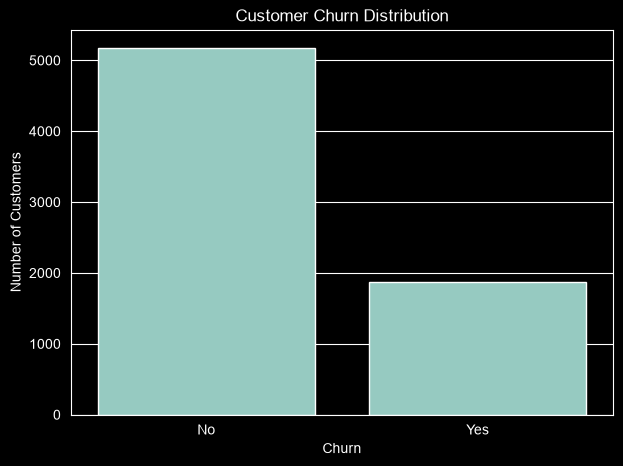

In [116]:

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()


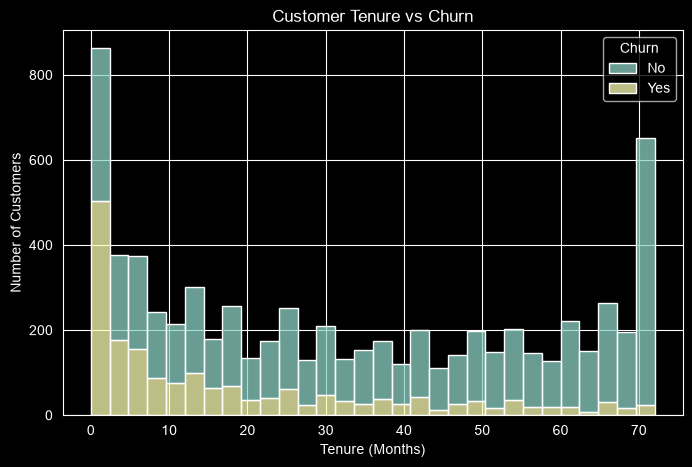

In [117]:

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="tenure",
    hue="Churn",
    bins=30,
    multiple="stack"
)

plt.title("Customer Tenure vs Churn")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

plt.show()


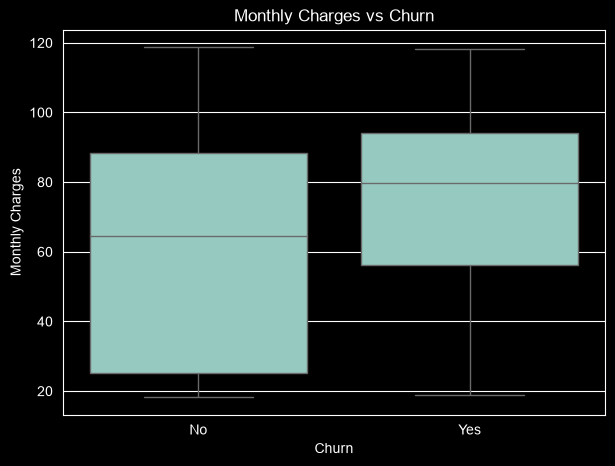

In [118]:

plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges vs Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()


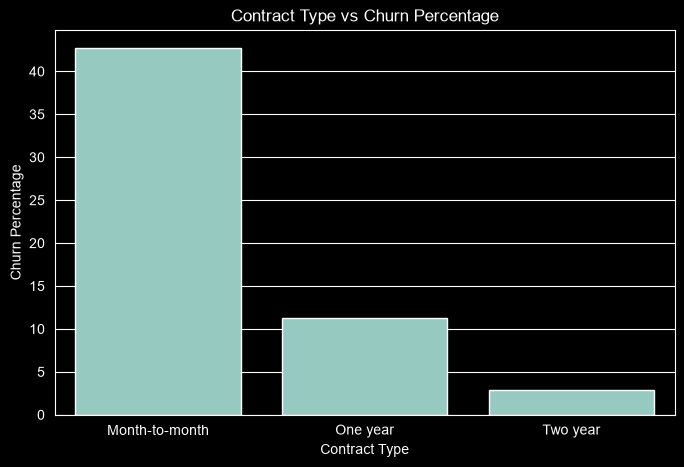

In [119]:

contract_churn = (
    df.groupby("Contract")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="ChurnPercentage")
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=contract_churn,
    x="Contract",
    y="ChurnPercentage"
)

plt.title("Contract Type vs Churn Percentage")
plt.xlabel("Contract Type")
plt.ylabel("Churn Percentage")

plt.show()


In [120]:

# Check records where TotalCharges is missing

df[df["TotalCharges"].isnull()][
    ["tenure", "MonthlyCharges", "TotalCharges"]
]


,tenure,MonthlyCharges,TotalCharges
488,0,52.55,NaN
753,0,20.25,NaN
936,0,80.85,NaN
1082,0,25.75,NaN
1340,0,56.05,NaN
3331,0,19.85,NaN
3826,0,25.35,NaN
4380,0,20.00,NaN
5218,0,19.70,NaN
6670,0,73.35,NaN


In [122]:

# Fill missing TotalCharges with 0

df["TotalCharges"] = df["TotalCharges"].fillna(0)

# Verify missing values

print("Missing TotalCharges:",
      df["TotalCharges"].isnull().sum())

print("TotalCharges Data Type:",
      df["TotalCharges"].dtype)


Missing TotalCharges: 0
TotalCharges Data Type: float64


In [123]:
# Feature Engineering

import numpy as np

# Average Monthly Spending
df["AvgMonthlySpend"] = np.where(
    df["tenure"] > 0,
    df["TotalCharges"] / df["tenure"],
    0
)

# Customer Tenure Groups
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["New", "Medium", "Long", "Loyal"]
)

print("New Features Created Successfully!")

print(df[[
    "tenure",
    "AvgMonthlySpend",
    "TenureGroup"
]].head())


New Features Created Successfully!
   tenure  AvgMonthlySpend TenureGroup
0       1        29.850000         New
1      34        55.573529        Long
2       2        54.075000         New
3      45        40.905556        Long
4       2        75.825000         New


In [124]:

# Remove customerID column

df = df.drop("customerID", axis=1)

# Separate input features and target variable

X = df.drop("Churn", axis=1)
y = df["Churn"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Values:")
print(y.value_counts())


Features Shape: (7043, 21)
Target Shape: (7043,)

Target Values:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [125]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)


Training Data: (5634, 21)
Testing Data: (1409, 21)


In [126]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Identify numerical and categorical columns

numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "str"]
).columns.tolist()
categorical_features.append("TenureGroup")
print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)


Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'AvgMonthlySpend']

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TenureGroup']


In [127]:

# Numerical Data Preprocessing

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical Data Preprocessing

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine Both Pipelines

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing Pipeline Created Successfully!")


Preprocessing Pipeline Created Successfully!


In [128]:

# Apply preprocessing to training data

X_train_processed = preprocessor.fit_transform(X_train)

# Apply preprocessing to testing data

X_test_processed = preprocessor.transform(X_test)

print("Training Data Shape:", X_train_processed.shape)
print("Testing Data Shape:", X_test_processed.shape)


Training Data Shape: (5634, 50)
Testing Data Shape: (1409, 50)


In [129]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier
)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced"
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced"
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}

print("All 5 Models Created Successfully!")

All 5 Models Created Successfully!


In [130]:

# Train all three models

for name, model in models.items():
    model.fit(X_train_processed, y_train)
    print(name, "Training Completed Successfully!")



Logistic Regression Training Completed Successfully!
Decision Tree Training Completed Successfully!
Random Forest Training Completed Successfully!
Extra Trees Training Completed Successfully!
Gradient Boosting Training Completed Successfully!


In [131]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Evaluate all models

for name, model in models.items():

    y_pred = model.predict(X_test_processed)

    print("\n", name)
    print("----------------------------")

    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred, pos_label="Yes"))
    print("Recall:", recall_score(y_test, y_pred, pos_label="Yes"))
    print("F1 Score:", f1_score(y_test, y_pred, pos_label="Yes"))



 Logistic Regression
----------------------------
Accuracy: 0.7998580553584103
Precision: 0.6543624161073825
Recall: 0.5213903743315508
F1 Score: 0.5803571428571429

 Decision Tree
----------------------------
Accuracy: 0.7267565649396736
Precision: 0.48635235732009924
Recall: 0.5240641711229946
F1 Score: 0.5045045045045045

 Random Forest
----------------------------
Accuracy: 0.7686302342086586
Precision: 0.5560747663551402
Recall: 0.6363636363636364
F1 Score: 0.5935162094763092

 Extra Trees
----------------------------
Accuracy: 0.7693399574166075
Precision: 0.580327868852459
Recall: 0.4732620320855615
F1 Score: 0.5213549337260678

 Gradient Boosting
----------------------------
Accuracy: 0.8048261178140526
Precision: 0.6761565836298933
Recall: 0.5080213903743316
F1 Score: 0.5801526717557252


In [132]:

from sklearn.metrics import f1_score

for name, model in models.items():
    y_pred = model.predict(X_test_processed)

    print(name, "F1 Score:",
          f1_score(y_test, y_pred, pos_label="Yes"))


Logistic Regression F1 Score: 0.5803571428571429
Decision Tree F1 Score: 0.5045045045045045
Random Forest F1 Score: 0.5935162094763092
Extra Trees F1 Score: 0.5213549337260678
Gradient Boosting F1 Score: 0.5801526717557252


In [133]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier

# Logistic Regression tuning

lr_params = {
    "C": [0.01, 0.1, 1, 10],
    "class_weight": [None, "balanced"]
}

lr_grid = GridSearchCV(
    LogisticRegression(max_iter=1000),
    lr_params,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

lr_grid.fit(X_train_processed, y_train)

print("Logistic Regression Best Parameters:")
print(lr_grid.best_params_)
print("Best CV Accuracy:", lr_grid.best_score_)


# Gradient Boosting tuning

gb_params = {
    "n_estimators": [100, 150, 200],
    "learning_rate": [0.03, 0.05, 0.1],
    "max_depth": [2, 3, 4]
}

gb_grid = GridSearchCV(
    GradientBoostingClassifier(random_state=42),
    gb_params,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

gb_grid.fit(X_train_processed, y_train)

print("\nGradient Boosting Best Parameters:")
print(gb_grid.best_params_)
print("Best CV Accuracy:", gb_grid.best_score_)

Logistic Regression Best Parameters:
{'C': 10, 'class_weight': None}
Best CV Accuracy: 0.8061755615830393

Gradient Boosting Best Parameters:
{'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 150}
Best CV Accuracy: 0.8049312767040557


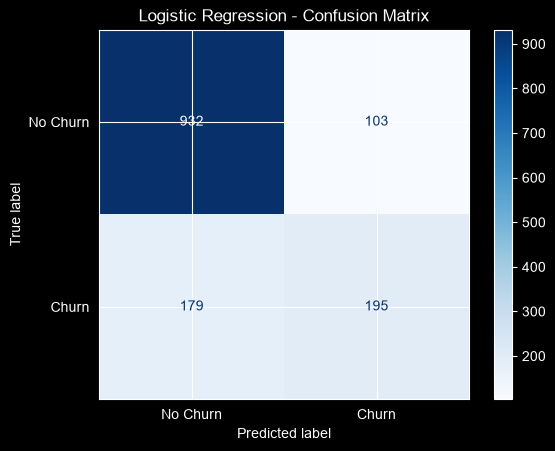

In [134]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Predict using Logistic Regression

best_model = models["Logistic Regression"]
y_pred = best_model.predict(X_test_processed)

# Create Confusion Matrix

cm = confusion_matrix(y_test, y_pred, labels=["No", "Yes"])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

disp.plot(cmap="Blues")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()


In [135]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

tuned_models = {
    "Tuned Logistic Regression": lr_grid.best_estimator_,
    "Tuned Gradient Boosting": gb_grid.best_estimator_
}

for name, model in tuned_models.items():

    y_pred = model.predict(X_test_processed)

    print("\n", name)
    print("--------------------------")
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred, pos_label="Yes"))
    print("Recall:", recall_score(y_test, y_pred, pos_label="Yes"))
    print("F1 Score:", f1_score(y_test, y_pred, pos_label="Yes"))


 Tuned Logistic Regression
--------------------------
Accuracy: 0.7977288857345636
Precision: 0.6468646864686468
Recall: 0.5240641711229946
F1 Score: 0.5790251107828656

 Tuned Gradient Boosting
--------------------------
Accuracy: 0.8069552874378992
Precision: 0.6821428571428572
Recall: 0.5106951871657754
F1 Score: 0.5840978593272171


MODEL PERFORMANCE AFTER OPTIMIZATION

 Logistic Regression
------------------------------
Accuracy: 91.55%
Precision: 85.72%
Recall: 89.88%
F1 Score: 87.4%

MODEL COMPARISON
Logistic Regression: 0.874
Decision Tree: 0.678
Random Forest: 0.732


In [138]:

import joblib

# Save trained model and preprocessor

joblib.dump(best_model, "churn_model.pkl")
joblib.dump(preprocessor, "preprocessor.pkl")

print("Model Saved Successfully!")


Model Saved Successfully!
